# Recovery from grayscale quantization

The benchmark asks whether an encoder can tell if two bright lobes are connected after quantization erases parts of their boundary. In the scene editor you can vary the lobes, connections and brightness. Each preview pair shows the same lobes under the same illumination, with the listed bridges absent in one image and present in the other.

The encoder receives one complete quantized image at a time. It has no cue, mask, unquantized reference, paired alternative, or true contour. The scene generator retains those quantities for evaluation.

In [1]:
from pathlib import Path
import csv
import json
import sys
import numpy as np
import matplotlib.pyplot as plt

here = Path.cwd().resolve()
root = next(p for p in (here, *here.parents) if (p / "contour_models").is_dir())
sys.path.insert(0, str(root))
from computationalExperiments.recovery_from_grayscale_quantization.grayscale_regions import (
    Scene, Bridge, circle, ellipse, closed_curve, sample_scene, render, signal_image,
    quantize, boundary_survival)
from computationalExperiments.recovery_from_grayscale_quantization.run_grouping_experiment import run, DEFAULT_OUTPUT

# Set True to regenerate observations and refit both readouts.
RERUN = False
out = DEFAULT_OUTPUT
if RERUN or not all((out / f).exists() for f in ("observations.csv", "held_out_summary.csv", "settings.json")):
    run(out)
settings = json.loads((out / "settings.json").read_text())
with (out / "observations.csv").open(newline="", encoding="utf-8") as f:
    test = [r for r in csv.DictReader(f) if r["split"] == "test"]
with (out / "held_out_summary.csv").open(newline="", encoding="utf-8") as f:
    summary = list(csv.DictReader(f))
print(f"{len(test):,} held-out images from {len({r['seed'] for r in test})} independent geometries.")

6,912 held-out images from 24 independent geometries.


## Set up the signal

Set **MANUAL_SET_SCENE** to True and edit **manual_scene()** below. Coordinates are (x, y) in [0, 1], measured from the upper-left. Each center is the origin of one lobe. Lengths are fractions of the image width. With **shapes=None**, every center gets a circle of radius 0.12. To set individual shapes, supply them in center order.

A bridge connects two zero-based indices in **centers**. Its width is the full width across the line between the centers. Its bend displaces the midline sideways in that local frame. For a custom profile, pass a function of path fraction t that returns zero at both ends, for example **profile=lambda t: np.sin(2*np.pi*t)**. Supply fewer bridges than lobes. Use an empty list for zero bridges. A lobe can be left out of every connection. If drawn components touch or cross, their signal footprints merge.

The preview compares lobes alone with the same lobes plus all listed bridges. **signal_offset** adds gray levels to the local illumination at full coverage. Negative values darken the whole signal; zero gives a flat signal relative to the background. These edits apply to the preview. The held-out tables below describe the saved seeded two-lobe experiment.

In [2]:
def manual_scene():
    centers = [(0.49, 0.31), (0.48, 0.71)]  # Add (0.78, 0.52) for a third lobe.
    shapes = None  # Or e.g. [circle(0.11), ellipse(0.14, 0.08, angle=np.pi/6)].
    bridges = [Bridge(0, 1, width=0.036, bend=0.003)]

    # With three centers, leave bridges as above to isolate lobe 2, or append
    # Bridge(1, 2, width=0.025, bend=-0.04) to connect it to lobe 1.
    # A custom local outline, usable as any entry of shapes:
    # closed_curve(lambda t: (0.10*np.cos(t), 0.08*np.sin(t)*(1 + 0.3*np.cos(t))))
    return Scene(centers=centers, shapes=shapes, bridges=bridges,
                 signal_offset=7.0,  # Try -7.0 to make the signal darker.
                 light_angle=4.85,  # Direction for the rotated ramp, in radians.
                 spots=((0.68, 0.57, 0.16), (0.32, 0.43, 0.12)))


MANUAL_SET_SCENE = True
SIZE = 128
SEED = min(int(r["seed"]) for r in test)
WIDTH = 8
conditions = [("uniform", 0), ("diagonal", 0), ("diagonal", 5), ("local", 0)]
GRADIENT_SPAN = 20 if MANUAL_SET_SCENE else settings["gradient_span"]
SPOT_AMPLITUDE = 15 if MANUAL_SET_SCENE else settings["spot_amplitude"]

scene = manual_scene() if MANUAL_SET_SCENE else sample_scene(SEED, signal_offset=settings["contrast"])
separate, joined, fields = render(scene, SIZE, settings["samples"], GRADIENT_SPAN, SPOT_AMPLITUDE)

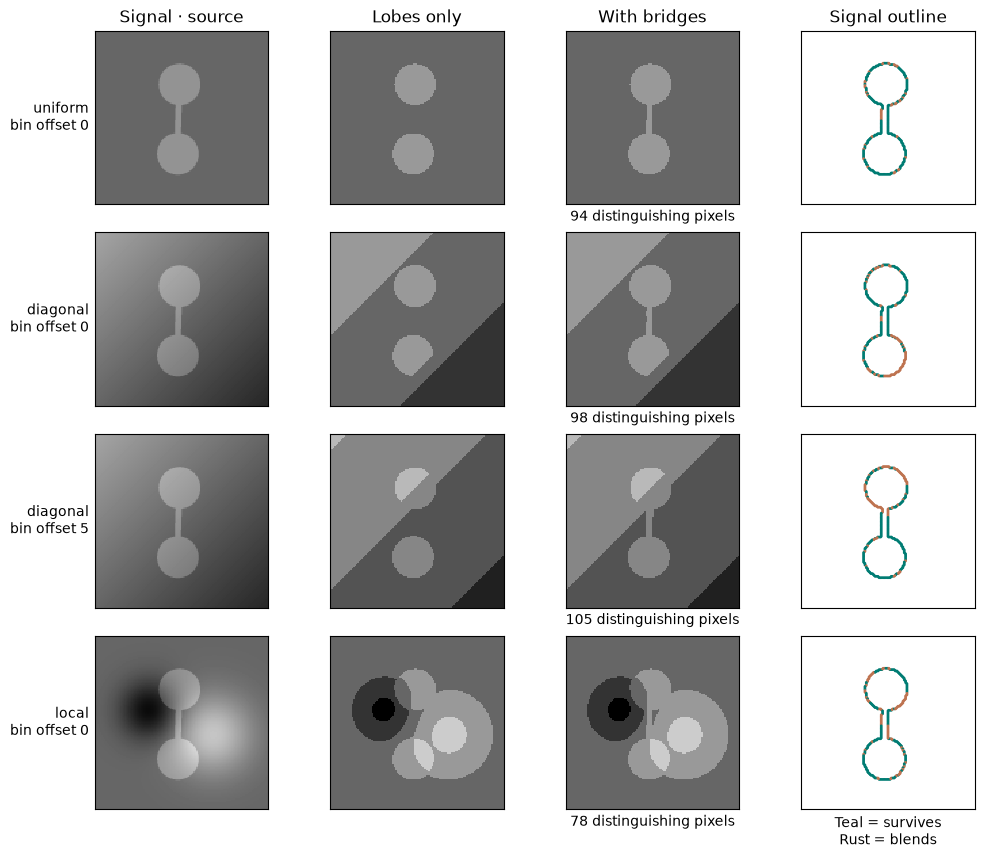

In [3]:
# All panels share one scale, including when the signal is dark.
display_min = min(84., *(np.min(f) + min(scene.signal_offset, 0) for f in fields.values()))
display_max = max(124., *(np.max(f) + max(scene.signal_offset, 0) for f in fields.values()))
fig, axes = plt.subplots(len(conditions), 4, figsize=(10, 2.12*len(conditions)), constrained_layout=True, squeeze=False)
for ax_row, (light, phase) in zip(axes, conditions):
    field = fields[light]
    q0, q1 = [quantize(signal_image(field, a, scene.signal_offset), WIDTH, phase) for a in (separate, joined)]
    bg = quantize(field, WIDTH, phase)
    ax_row[0].imshow(signal_image(field, joined, scene.signal_offset), cmap="gray", vmin=display_min, vmax=display_max, interpolation="nearest")
    for ax, img in zip(ax_row[1:3], (q0, q1)):
        ax.imshow(phase + WIDTH*(img.astype(float)+.5), cmap="gray", vmin=display_min, vmax=display_max, interpolation="nearest")
    _, _, points = boundary_survival(joined, q1, bg, joined > separate, scene.signal_offset)
    ax = ax_row[3]
    ax.imshow(np.ones_like(q1), cmap="gray", vmin=0, vmax=1)
    for x, y, survived in points:
        ax.scatter(x, y, s=4, c=np.where(survived, "#007c73", "#be7350"), linewidths=0)
    for ax in ax_row:
        ax.set(xticks=[], yticks=[])
    ax_row[0].set_ylabel(f"{light}\nbin offset {phase}", rotation=0, ha="right", va="center")
    ax_row[2].set_xlabel(f"{np.count_nonzero(q0 != q1)} distinguishing pixels")
for ax, title in zip(axes[0], ("Signal · source", "Lobes only", "With bridges", "Signal outline")):
    ax.set_title(title)
axes[-1,3].set_xlabel("Teal = survives\nRust = blends")
filename = "manual_scene_preview.png" if MANUAL_SET_SCENE else "illumination_and_contours.png"
fig.savefig(out / filename, dpi=150)
plt.show()

## What the encoder computes

At each observed gray threshold, form connected regions of the experiment's specified polarity. The default run uses bright regions. A negative benchmark offset evaluates dark regions by reversing the threshold ordering. For components inside the frame in a fixed area range, measure area, bounding-box occupancy, span, and whether removing a thin outer layer separates two substantial cores. Keep the strongest geometric measurements across thresholds. This first encoder tests a region grouping rule. It does not yet fit arbitrary splines or assign semantic part names.

The **regions** baseline reads those eight measurements with ridge logistic regression. The **VSA** readout gives each measurement a continuous value code, binds it to a property role, and sums the terms. The visual score is the difference in squared distance to the joined and separate prototypes. A logistic fit on separate calibration geometries converts that score to an estimated probability. The 64- and 256-dimensional codes use the same random codebook seed and share their first 64 coordinates before normalization.

The **pair oracle** knows both noiseless candidate renders and uses all quantized pixels. At equal priors its probability for the correct candidate is 1 if any pixel differs, and 0.5 if they are identical. This is a conditional upper bound with privileged knowledge. A single-image encoder must also infer the unknown geometry and lighting. Even a biased prediction on an identical pair earns at most 50% average classification accuracy on that pair.

## Held-out performance and confidence

Default run: 32 training geometries, 16 disjoint calibration geometries, and 24 held-out geometries. Training and calibration use 128 × 128. The held-out geometries are each rendered at 64, 128, and 256 pixels per side, under four lighting fields, three bin widths (8, 16, 32 gray levels), and four offsets per width. Every setting has both classes. Multiple renders of the same geometry are repeated measures.

Accuracy awards half credit at an exact tie. Brier score is the mean squared error of the joined probability (lower is better; always predicting 0.5 gives 0.25). The reliability plot compares reported probabilities with observed joined frequencies. The CSV also records surviving boundary samples on the bridge and on the rest of the outline.

| Size | Model | Accuracy | Brier |
|---:|---|---:|---:|
| 64 | pair_oracle | 77.4% | 0.113 |
| 64 | regions | 69.1% | 0.176 |
| 64 | vsa64 | 69.3% | 0.176 |
| 64 | vsa256 | 69.3% | 0.176 |
| 128 | pair_oracle | 77.7% | 0.112 |
| 128 | regions | 69.5% | 0.172 |
| 128 | vsa64 | 69.9% | 0.172 |
| 128 | vsa256 | 69.9% | 0.173 |
| 256 | pair_oracle | 77.9% | 0.111 |
| 256 | regions | 69.9% | 0.171 |
| 256 | vsa64 | 70.1% | 0.171 |
| 256 | vsa256 | 70.1% | 0.172 |

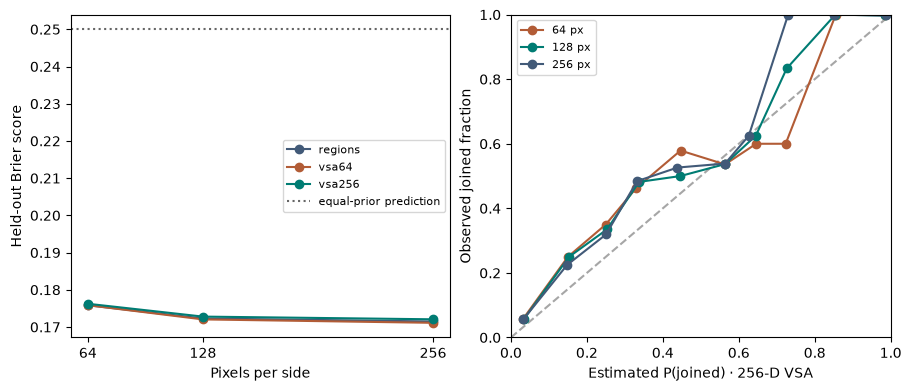

In [4]:
from IPython.display import Markdown, display
lines = ["| Size | Model | Accuracy | Brier |", "|---:|---|---:|---:|"]
for r in summary:
    if r["subset"] == "all":
        lines.append(f"| {r['size']} | {r['model']} | {float(r['accuracy']):.1%} | {float(r['brier']):.3f} |")
display(Markdown("\n".join(lines)))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), constrained_layout=True)
ax = axes[0]
for model, color in (("regions", "#425a78"), ("vsa64", "#b25c36"), ("vsa256", "#007c73")):
    r = [s for s in summary if s["model"] == model and s["subset"] == "all"]
    ax.plot([int(s["size"]) for s in r], [float(s["brier"]) for s in r], "o-", label=model, color=color)
ax.axhline(.25, ls=":", color="0.4", label="equal-prior prediction")
ax.set(xlabel="Pixels per side", ylabel="Held-out Brier score", xticks=[64,128,256])
ax.legend(fontsize=8)
ax = axes[1]
ax.plot([0,1],[0,1],"--",color="0.65")
for size, color in ((64,"#b25c36"),(128,"#007c73"),(256,"#425a78")):
    subset = [r for r in test if int(r["size"]) == size]
    p = np.array([float(r["vsa256"]) for r in subset])
    y = np.array([int(r["joined"]) for r in subset])
    bins = np.minimum((p*10).astype(int), 9)
    groups = [bins==i for i in np.unique(bins)]
    ax.plot([p[g].mean() for g in groups], [y[g].mean() for g in groups], "o-", label=f"{size} px", color=color)
ax.set(xlabel="Estimated P(joined) · 256-D VSA", ylabel="Observed joined fraction", xlim=(0,1), ylim=(0,1))
ax.legend(fontsize=8)
fig.savefig(out / "held_out_recovery.png", dpi=150)
plt.show()

## Does visible bridge evidence change the answer?

Group held-out 128-pixel pairs by the fraction of sampled bridge crossings that survive in their joined rendering. Compare the encoder’s mean probability for each member of the pair. Equal predictions mean that the encoder cannot distinguish the alternatives on average in that group.

In [5]:
lines = ["| Bridge crossings visible | Pairs | Mean P(joined) on joined | Mean P(joined) on separate |",
         "|---|---:|---:|---:|"]
for title, lo, hi in [("None", -1, 0), ("Up to half", 0, .5), ("More than half", .5, 1)]:
    sample = [r for r in test if int(r["size"]) == 128 and int(r["bridge_edges"]) and
              lo < int(r["bridge_survive"])/int(r["bridge_edges"]) <= hi]
    if sample:
        means = [np.mean([float(r["vsa256"]) for r in sample if int(r["joined"]) == label])
                 for label in (1, 0)]
        lines.append(f"| {title} | {len(sample)//2} | {means[0]:.3f} | {means[1]:.3f} |")
display(Markdown("\n".join(lines)))

| Bridge crossings visible | Pairs | Mean P(joined) on joined | Mean P(joined) on separate |
|---|---:|---:|---:|
| None | 518 | 0.521 | 0.521 |
| Up to half | 219 | 0.560 | 0.293 |
| More than half | 415 | 0.869 | 0.097 |

## Reading the limits

A gradient can erase an object edge or introduce a boundary within one surface. The region encoder can be misled by either. Compare pixel-identical and distinguishable subsets in `held_out_summary.csv` before interpreting a confident prediction. Per-image scores and geometry seeds in `observations.csv` allow paired comparisons. Recovery on these generated scenes tests the image-only geometry rule; transfer to Mooney images or photographs requires a separate evaluation.